In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("AReM")
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
for activity in activities:
    files = list((data_path / activity).glob("*.csv"))
    print(f"Activity: {activity}, Number of files: {len(files)}")

Activity: bending1, Number of files: 7
Activity: bending2, Number of files: 6
Activity: cycling, Number of files: 15
Activity: lying, Number of files: 15
Activity: sitting, Number of files: 15
Activity: standing, Number of files: 15
Activity: walking, Number of files: 15


In [ ]:
#1b 
train_files = []
test_files = []
for activity in activities:
    folder = data_path / activity
    files = sorted(folder.glob("*.csv"),
                   key=lambda f: int(f.stem.replace("dataset", "")))

    if activity in ["bending1", "bending2"]:
        test_files.extend(files[:2])
        train_files.extend(files[2:])
    else:
        test_files.extend(files[:3])
        train_files.extend(files[3:])
print("Training files:", len(train_files))
print("Testing files:", len(test_files))

# figuring out shape
sample_file = train_files[0]
df = pd.read_csv(sample_file, comment="#",header=None)
print("File", sample_file)
print("Shape", df.shape)
display(df.head())

Training files: 69
Testing files: 19
File AReM/bending1/dataset3.csv
Shape (480, 7)


,0,1,2,3,4,5,6
0,0,42.00,0.71,21.25,0.43,30.00,0.00
1,250,41.50,0.50,20.25,1.48,31.25,1.09
2,500,41.50,0.50,14.25,1.92,33.00,0.00
3,750,40.75,0.83,15.75,0.43,33.00,0.00
4,1000,40.00,0.71,20.00,2.74,32.75,0.43


In [ ]:
def load_arem_file(file):
    with open(file, "r") as f:
        lines = [
            line.rstrip("\r\n").rstrip(",")
            for line in f
            if line.strip() and not line.lstrip().startswith("#") ]

    from io import StringIO
    text = "\n".join(lines)
    if "," in lines[0]:
        df = pd.read_csv(StringIO(text), header=None)
    else:
        df = pd.read_csv(StringIO(text), header=None, sep=r"\s+")
    return df

In [ ]:
#1c. ii
sensor_data = df.iloc[:, 1:]
print("Sensor data shape:", sensor_data.shape)
features = sensor_data.agg(['mean', 'std', 'min', 'max', 'median'])
print(features)

#q1, q3
q1 = sensor_data.quantile(0.25)
q3 = sensor_data.quantile(0.75)
print("Q1:", q1)    
print("Q3:", q3)

features.loc["q1"] = q1
features.loc["q3"] = q3
display(features)

feature_rows= []
for file in train_files + test_files:
    df = load_arem_file(file)
    sensor_data = df.iloc[:, 1:]
    row = {}
    for i, col in enumerate(sensor_data.columns, start=1):
        values = sensor_data[col]
        row[f"sensor_{i}_mean"] = values.mean()
        row[f"sensor_{i}_std"] = values.std()
        row[f"sensor_{i}_min"] = values.min()
        row[f"sensor_{i}_max"] = values.max()
        row[f"sensor_{i}_median"] = values.median()
        row[f"sensor_{i}_q1"] = values.quantile(0.25)
        row[f"sensor_{i}_q3"] = values.quantile(0.75)
    feature_rows.append(row)
feature_df = pd.DataFrame(feature_rows)
print("Feature DataFrame shape:", feature_df.shape)
display(feature_df.head())
print(feature_df.shape) # confirming shape is good to go

Sensor data shape: (480, 6)
                1        2          3         4          5         6
mean    43.954500  0.42625  22.122354  0.497312  35.588458  0.493292
std      1.558835  0.33869   3.030943  0.550657   1.999604  0.513506
min     35.000000  0.00000   6.500000  0.000000  29.000000  0.000000
max     47.400000  1.70000  29.750000  4.440000  38.500000  1.790000
median  44.330000  0.47000  23.000000  0.430000  36.000000  0.430000
Q1: 1    43.0000
2     0.0000
3    19.7500
4     0.0000
5    35.3625
6     0.0000
Name: 0.25, dtype: float64
Q3: 1    45.00
2     0.50
3    24.00
4     0.83
5    36.50
6     0.94
Name: 0.75, dtype: float64


,1,2,3,4,5,6
mean,43.954500,0.42625,22.122354,0.497312,35.588458,0.493292
std,1.558835,0.33869,3.030943,0.550657,1.999604,0.513506
min,35.000000,0.00000,6.500000,0.000000,29.000000,0.000000
max,47.400000,1.70000,29.750000,4.440000,38.500000,1.790000
median,44.330000,0.47000,23.000000,0.430000,36.000000,0.430000
q1,43.000000,0.00000,19.750000,0.000000,35.362500,0.000000
q3,45.000000,0.50000,24.000000,0.830000,36.500000,0.940000


Feature DataFrame shape: (88, 42)


,sensor_1_mean,sensor_1_std,sensor_1_min,sensor_1_max,sensor_1_median,sensor_1_q1,sensor_1_q3,sensor_2_mean,sensor_2_std,sensor_2_min,...,sensor_5_median,sensor_5_q1,sensor_5_q3,sensor_6_mean,sensor_6_std,sensor_6_min,sensor_6_max,sensor_6_median,sensor_6_q1,sensor_6_q3
0,43.954500,1.558835,35.00,47.40,44.33,43.00,45.00,0.426250,0.338690,0.0,...,36.00,35.3625,36.50,0.493292,0.513506,0.0,1.79,0.43,0.00,0.94
1,42.179812,3.670666,33.00,47.75,43.50,39.15,45.00,0.696042,0.630860,0.0,...,35.00,30.4575,36.33,0.613521,0.524317,0.0,2.18,0.50,0.00,1.00
2,41.678063,2.243490,33.00,45.75,41.75,41.33,42.75,0.535979,0.405469,0.0,...,30.00,28.4575,31.25,0.383292,0.389164,0.0,1.79,0.43,0.00,0.50
3,43.454958,1.386098,37.00,48.00,43.25,42.50,45.00,0.378083,0.315566,0.0,...,23.50,22.2500,24.00,0.679646,0.622534,0.0,5.26,0.50,0.43,0.87
4,43.969125,1.618364,36.25,48.00,44.50,43.31,44.67,0.413125,0.263111,0.0,...,21.67,20.5000,23.75,0.555312,0.487826,0.0,2.96,0.49,0.00,0.83


(88, 42)


In [11]:
# 1ciii std and 90% bootstrap CI 
feature_std = feature_df.std()
display(feature_std)

import numpy as np
np.random.seed(42) 
n_bootstrap = 1000
bootstrap_stds = []

for i in range(n_bootstrap):
    sample = feature_df.sample(n=len(feature_df), replace=True)
    bootstrap_stds.append(sample.std().values)

bootstrap_stds = np.array(bootstrap_stds)
lower = np.percentile(bootstrap_stds, 5, axis=0)
upper = np.percentile(bootstrap_stds, 95, axis=0)  

std_results = pd.DataFrame({
    "Feature": feature_df.columns,
    "Standard Deviation": feature_df.std().values,
    "90% CI Lower": lower,
    "90% CI Upper": upper})

display(std_results.round(3))

sensor_1_mean      5.335718
sensor_1_std       1.772153
sensor_1_min       9.569975
sensor_1_max       4.394362
sensor_1_median    5.440054
sensor_1_q1        6.153590
sensor_1_q3        5.138925
sensor_2_mean      1.574164
sensor_2_std       0.884105
sensor_2_min       0.000000
sensor_2_max       5.062729
sensor_2_median    1.412244
sensor_2_q1        0.946386
sensor_2_q3        2.125266
sensor_3_mean      4.008380
sensor_3_std       0.946710
sensor_3_min       2.956462
sensor_3_max       4.875137
sensor_3_median    4.036396
sensor_3_q1        4.220658
sensor_3_q3        4.171628
sensor_4_mean      1.166114
sensor_4_std       0.458242
sensor_4_min       0.000000
sensor_4_max       2.183625
sensor_4_median    1.145586
sensor_4_q1        0.843620
sensor_4_q3        1.552504
sensor_5_mean      5.675593
sensor_5_std       1.024898
sensor_5_min       6.124001
sensor_5_max       5.741238
sensor_5_median    5.813782
sensor_5_q1        6.096465
sensor_5_q3        5.531720
sensor_6_mean      1

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,sensor_1_mean,5.336,4.696,5.851
1,sensor_1_std,1.772,1.570,1.948
2,sensor_1_min,9.570,8.238,10.737
3,sensor_1_max,4.394,3.362,5.352
4,sensor_1_median,5.440,4.793,5.990
5,sensor_1_q1,6.154,5.565,6.624
6,sensor_1_q3,5.139,4.290,5.845
7,sensor_2_mean,1.574,1.407,1.704
8,sensor_2_std,0.884,0.807,0.943
9,sensor_2_min,0.000,0.000,0.000


Training data shape: (69, 43)
Class distribution:
class
0    60
1     9
Name: count, dtype: int64


,sensor_1_mean,sensor_1_std,sensor_1_max,sensor_2_mean,sensor_2_std,sensor_2_max,sensor_6_mean,sensor_6_std,sensor_6_max,class
0,43.954500,1.558835,47.40,0.426250,0.338690,1.70,0.493292,0.513506,1.79,1
1,42.179812,3.670666,47.75,0.696042,0.630860,3.00,0.613521,0.524317,2.18,1
2,41.678063,2.243490,45.75,0.535979,0.405469,2.83,0.383292,0.389164,1.79,1
3,43.454958,1.386098,48.00,0.378083,0.315566,1.58,0.679646,0.622534,5.26,1
4,43.969125,1.618364,48.00,0.413125,0.263111,1.50,0.555312,0.487826,2.96,1


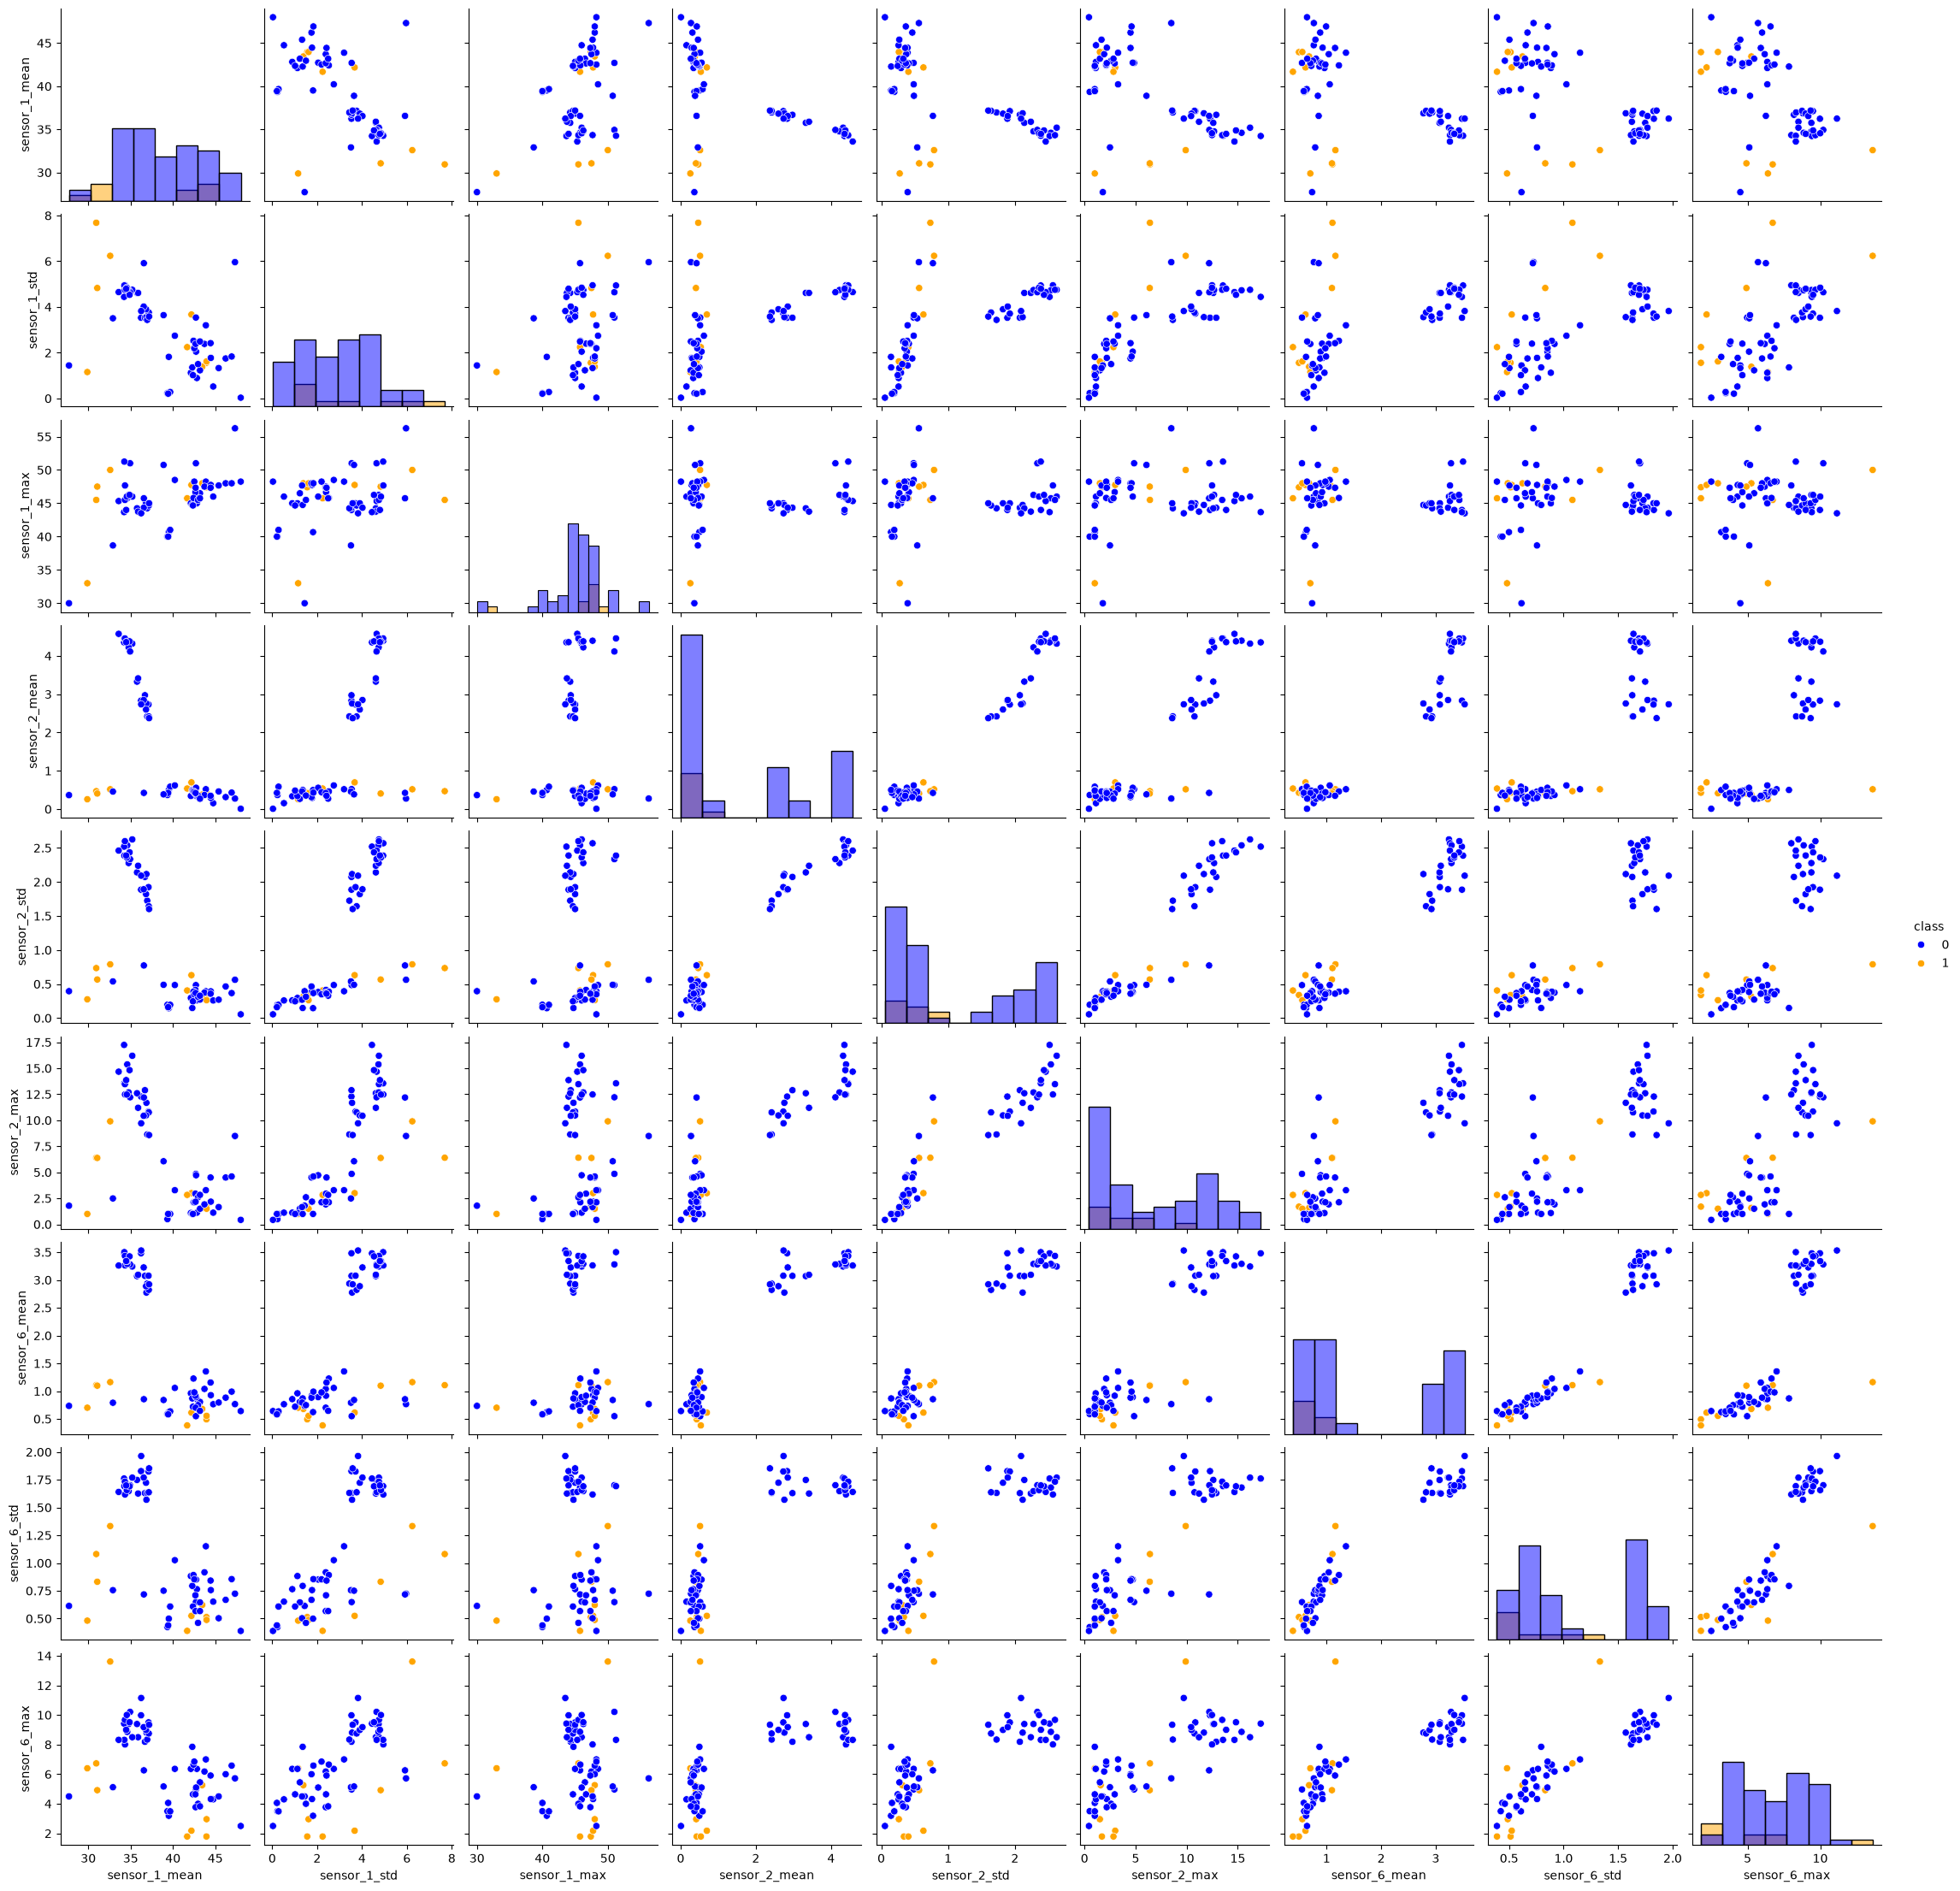

In [12]:
# question 4

train_features = feature_df.iloc[:len(train_files)].copy()
train_labels = [ 1 if file.parent.name in ["bending1", "bending2"] else 0 for file in train_files]
train_features['class'] = train_labels
print("Training data shape:", train_features.shape)
print("Class distribution:")
print(train_features['class'].value_counts())


#selected features (mean, std, max)
selected_features = []
for i in [1, 2, 6]:
    selected_features.extend([
        f"sensor_{i}_mean",
        f"sensor_{i}_std",
        f"sensor_{i}_max" ])
plot_data = train_features[selected_features + ["class"]]
display(plot_data.head())

import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(plot_data, vars=selected_features, hue="class", palette={0: "blue", 1: "orange"}, diag_kind="hist")
plt.show()


Shape: (69, 37)


,sensor_1_part1_mean,sensor_1_part1_std,sensor_1_part1_max,sensor_1_part2_mean,sensor_1_part2_std,sensor_1_part2_max,sensor_2_part1_mean,sensor_2_part1_std,sensor_2_part1_max,sensor_2_part2_mean,...,sensor_5_part2_mean,sensor_5_part2_std,sensor_5_part2_max,sensor_6_part1_mean,sensor_6_part1_std,sensor_6_part1_max,sensor_6_part2_mean,sensor_6_part2_std,sensor_6_part2_max,class
0,44.057167,1.556971,46.50,43.851833,1.557168,47.40,0.381042,0.329540,1.50,0.471458,...,34.883375,2.298693,38.25,0.598250,0.526656,1.79,0.388333,0.478528,1.50,1
1,43.278875,3.473355,47.75,41.080750,3.537481,46.00,0.673292,0.634285,3.00,0.718792,...,30.965708,3.760118,38.50,0.640958,0.554542,1.53,0.586083,0.491873,2.18,1
2,41.621208,3.118644,45.75,41.734917,0.595920,43.67,0.623083,0.489595,2.83,0.448875,...,29.635833,2.062647,36.00,0.419083,0.411200,1.79,0.347500,0.363144,1.50,1
3,44.117042,1.359836,48.00,42.792875,1.058792,46.50,0.250042,0.314099,1.30,0.506125,...,22.850875,1.881721,26.00,0.815417,0.718016,5.26,0.543875,0.473445,4.06,1
4,43.486208,1.281976,45.00,44.452042,1.771251,48.00,0.378667,0.284434,1.30,0.447583,...,21.882042,1.929494,26.00,0.524875,0.486847,2.28,0.585750,0.487918,2.96,1


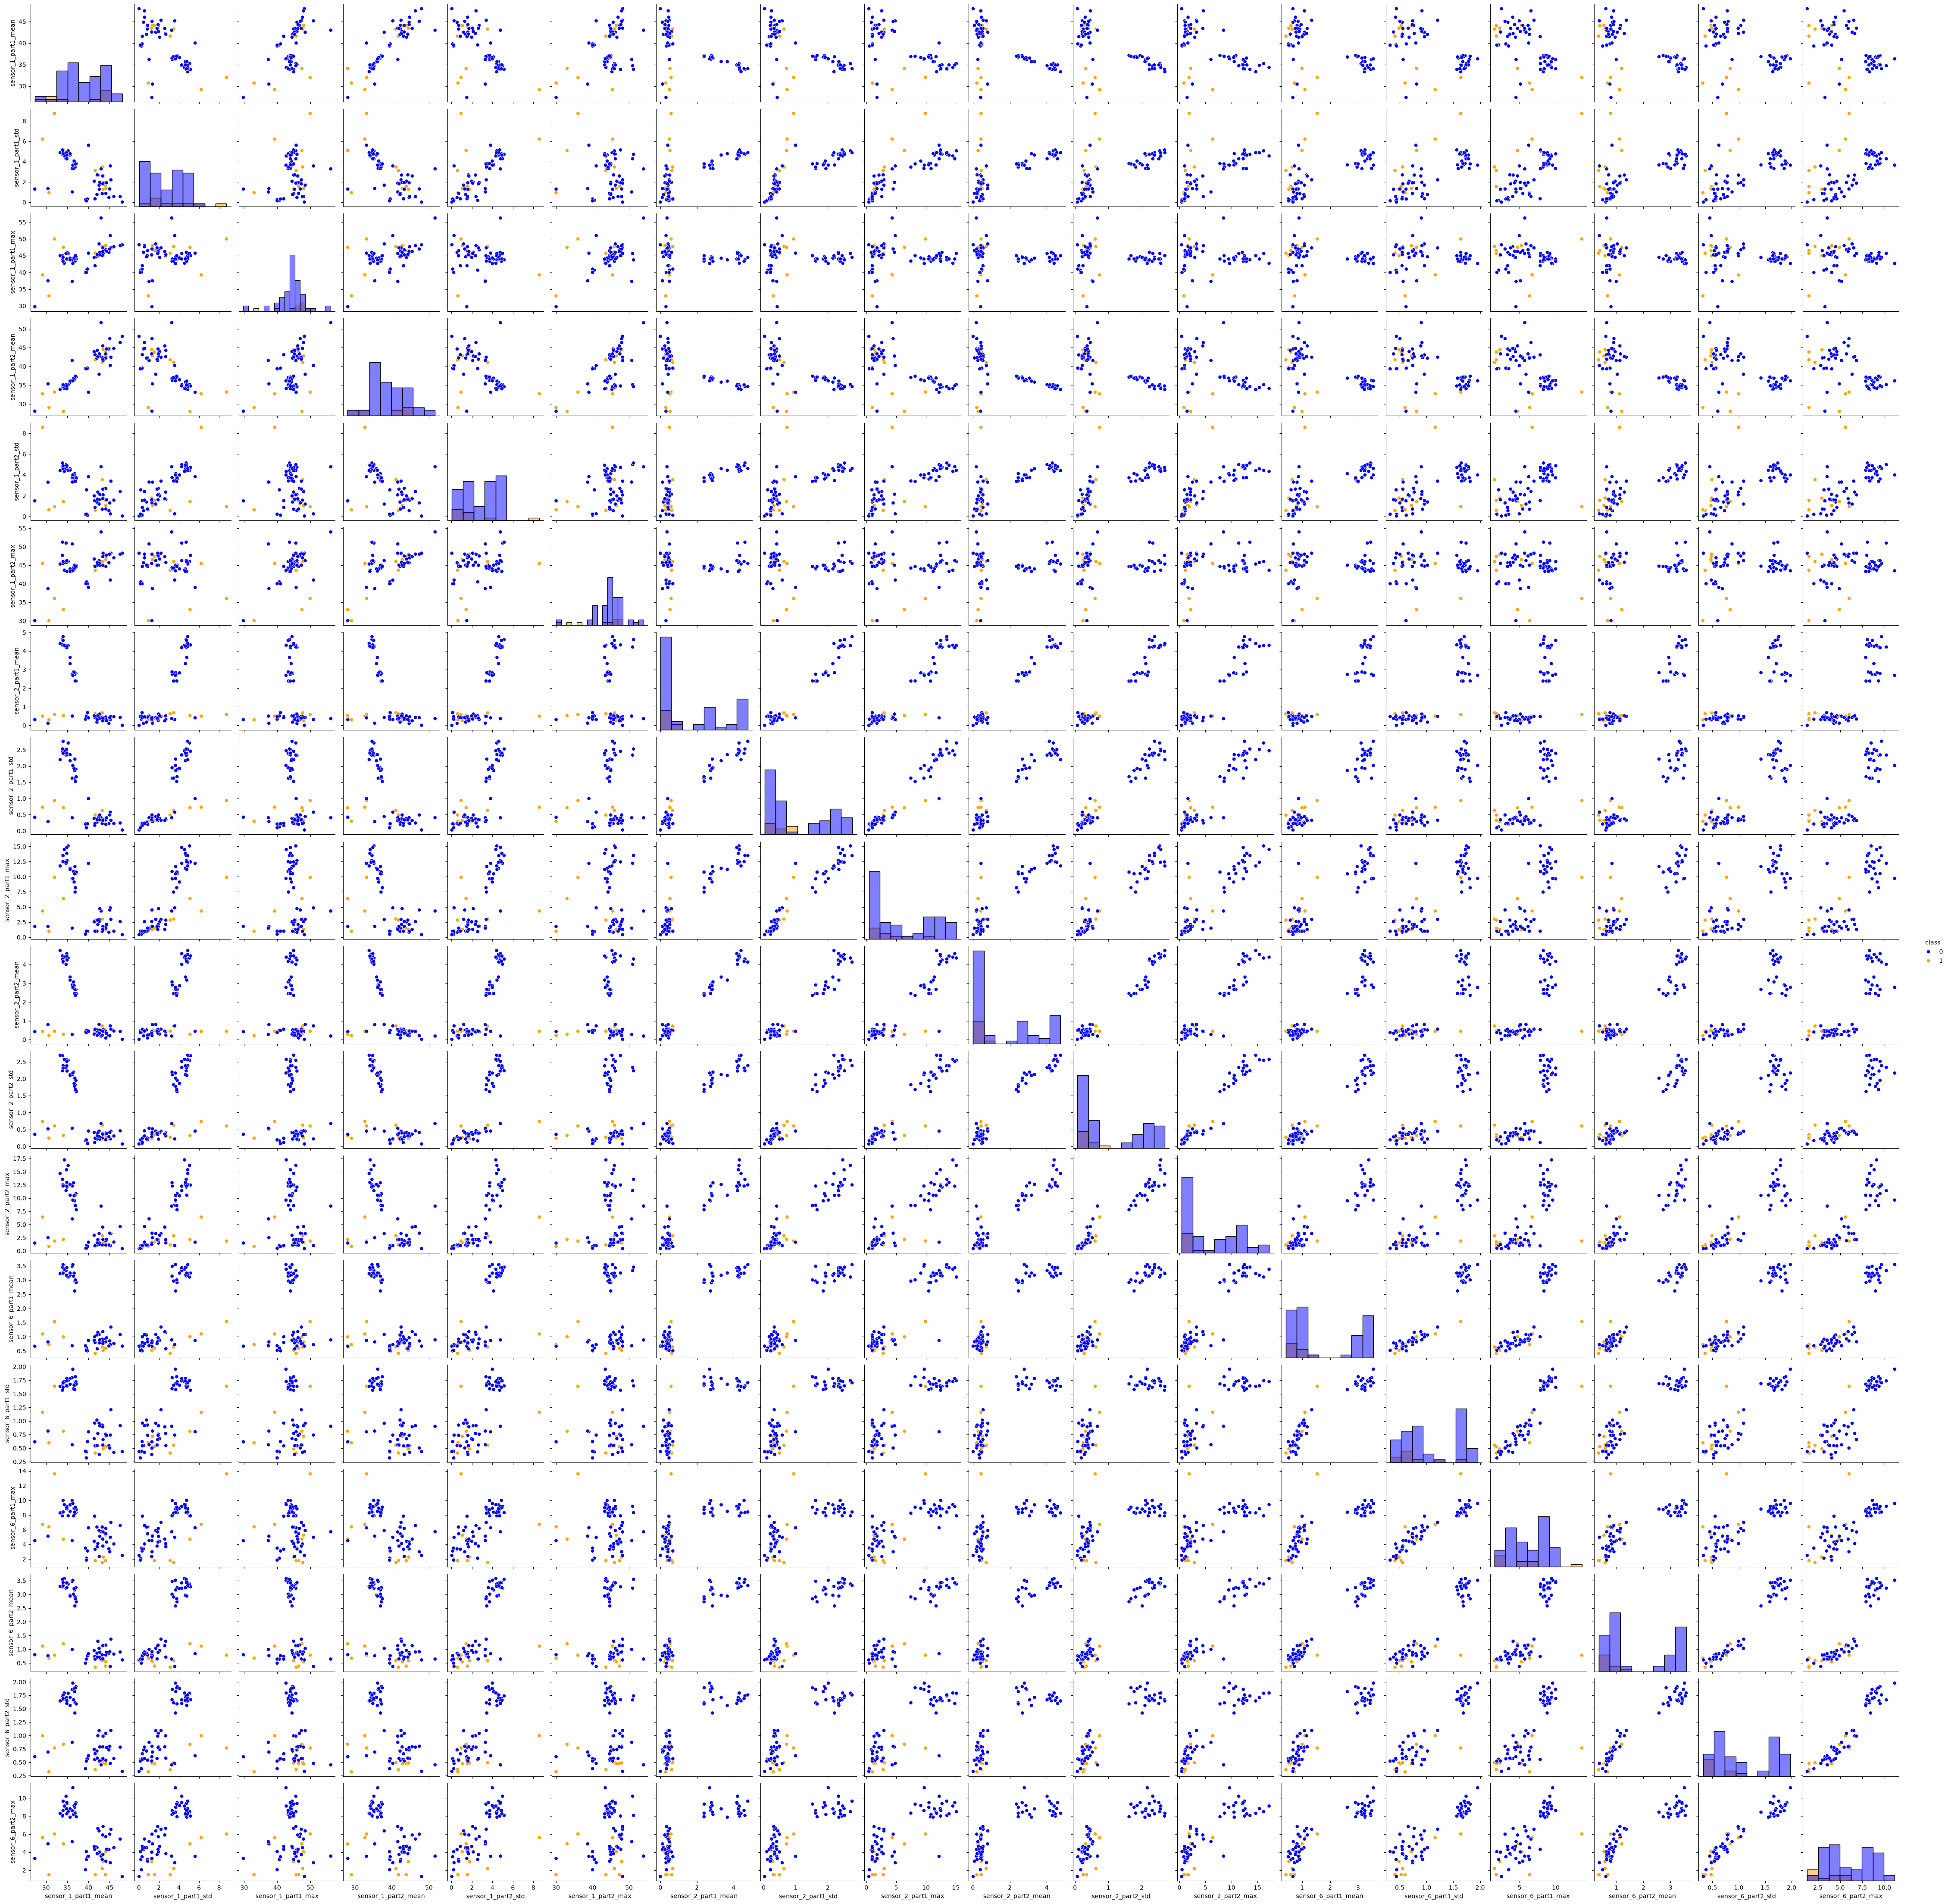

In [13]:
#4aii

split_rows = []
for file in train_files:
    df = load_arem_file(file)
    sensor_data = df.iloc[:, 1:]
    row = {}

    for i, col in enumerate(sensor_data.columns, start=1):
        values = sensor_data[col]
        segments = np.array_split(values.to_numpy(), 2)

        for j, segment in enumerate(segments, start=1):
            row[f"sensor_{i}_part{j}_mean"] = np.mean(segment)
            row[f"sensor_{i}_part{j}_std"] = np.std(segment, ddof=1)
            row[f"sensor_{i}_part{j}_max"] = np.max(segment)
    row["class"] = (
        1 if file.parent.name in ["bending1", "bending2"] else 0)
    split_rows.append(row)
split_features = pd.DataFrame(split_rows)
print("Shape:", split_features.shape)
display(split_features.head())

# scatterplot portion
selected_split_features = []
for i in [1, 2, 6]:
    for j in [1, 2]:
        selected_split_features.extend([
            f"sensor_{i}_part{j}_mean",
            f"sensor_{i}_part{j}_std",
            f"sensor_{i}_part{j}_max"])
sns.pairplot(split_features, vars= selected_split_features, hue="class", palette={0: "blue", 1: "orange"}, diag_kind="hist")

In [ ]:
#4a iii
def extract_segment_features(files, l):
    rows = []
    labels = []
    for file in files:
        df = load_arem_file(file)
        sensor_data = df.iloc[:, 1:]
        row = {}
        for i, col in enumerate(sensor_data.columns, start=1):
            values = sensor_data[col]
            segments = np.array_split(values.to_numpy(), l)
            for j, segment in enumerate(segments, start=1):
                row[f"sensor_{i}_part{j}_min"] = np.min(segment)
                row[f"sensor_{i}_part{j}_max"] = np.max(segment)
                row[f"sensor_{i}_part{j}_mean"] = np.mean(segment)
                row[f"sensor_{i}_part{j}_median"] = np.median(segment)
                row[f"sensor_{i}_part{j}_std"] = np.std(segment, ddof=1)
                row[f"sensor_{i}_part{j}_q1"] = np.percentile(segment, 25)
                row[f"sensor_{i}_part{j}_q3"] = np.percentile(segment, 75)
        rows.append(row)
        labels.append(1 if file.parent.name in ["bending1", "bending2"] else 0)
    X = pd.DataFrame(rows)
    y = pd.Series(labels)
    return X, y

# training and testing function 
X_train1, y_train1 = extract_segment_features(train_files, 1)
X_train2, y_train2 = extract_segment_features(train_files, 2)
print("l=1", X_train1.shape)
print("l=2", X_train2.shape)
print("Labels:", np.bincount(y_train1))

# setup
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)
print(cv)


results = []
p_values = [1,2,3,5,10,15,20]

for l in range(1,21):
    X,y = extract_segment_features(train_files, l)
    for p in p_values:
        if p > X.shape[1]:
            continue
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(estimator=LogisticRegression(max_iter=1000, C=1e6),
                n_features_to_select=p,
                step=0.2 )),
            ("logistic", LogisticRegression(
                max_iter=1000,
                C=1e6 ))  ])

        scores = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="accuracy" )

        results.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores.mean(),
            "CV Std": scores.std() })

cv_results = pd.DataFrame(results)
display(
    cv_results.sort_values(
        "CV Accuracy",
        ascending=False ).head(10))

best_result = cv_results.sort_values(
    ["CV Accuracy", "p", "l"],
    ascending=[False, True, True]
).iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
print(f"Best l: {best_l}, Best p: {best_p}")
print("Best CV Accuracy:", round(best_result["CV Accuracy"], 4))

l=1 (69, 42)
l=2 (69, 84)
Labels: [60  9]
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


,l,p,CV Accuracy,CV Std
139,20,20,0.971429,0.057143
41,6,20,0.971429,0.034993
131,19,15,0.971429,0.034993
4,1,10,0.971429,0.034993
5,1,15,0.971429,0.034993
26,4,15,0.971429,0.034993
9,2,3,0.971429,0.034993
110,16,15,0.970330,0.036380
109,16,10,0.969231,0.061538
132,19,20,0.957143,0.057143


Best l: 2, Best p: 3
Best CV Accuracy: 0.9714


Confusion Matrix:
[[60  0]
 [ 0  9]]
Training AUC: 1.0


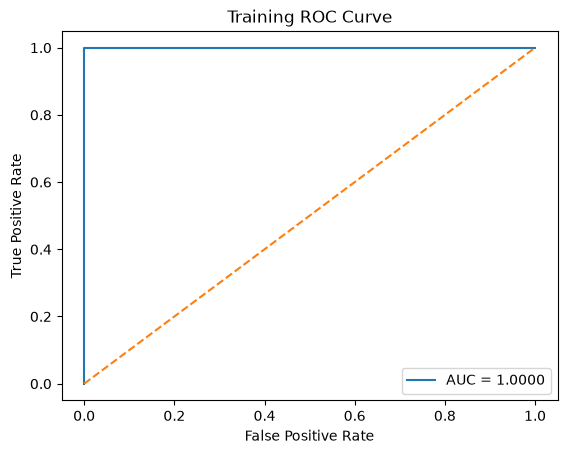

,Feature,Coefficient
0,sensor_3_part1_min,-8.873080
1,sensor_5_part1_min,19.777683
2,sensor_5_part1_max,14.865645


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        14:34:40   Log-Likelihood:            -2.3831e-08
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -83.1346   5.72e+04     -0.001      0.999   -1.12e+05    1.12e+05
x1           -31.7767   7.44e+04     -0.000      1.000   -1.46e+05    1.46e+05
x2            68.2927   5.73e+04      0.001      0.9

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [16]:
#4a iv
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

X_train, y_train = extract_segment_features(train_files, best_l)
best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(estimator=LogisticRegression(max_iter=1000, C=1e6),
        n_features_to_select=best_p,
        step=0.2 )),
    ("logistic", LogisticRegression(
        max_iter=1000,
        C=1e6 ))  ])

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_train)
y_prob = best_model.predict_proba(X_train)[:,1]

print("Confusion Matrix:")
print(confusion_matrix(y_train, y_pred))
print("Training AUC:", roc_auc_score(y_train, y_prob))
fpr, tpr, thresholds = roc_curve(y_train, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_train, y_prob):.4f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()


#4a iv coefficients
selected_features = X_train.columns[best_model.named_steps["rfe"].support_]
coefficients = best_model.named_steps["logistic"].coef_[0]
coef_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients})
display(coef_df)

# p-values
import statsmodels.api as sm
X_scaled = best_model.named_steps["scaler"].transform(X_train)
X_selected = X_scaled[:, best_model.named_steps["rfe"].support_]
X_sm = sm.add_constant(X_selected)
logit_model = sm.Logit(y_train, X_sm)
logit_result = logit_model.fit(disp=False)
print(logit_result.summary())

In [17]:
# 4a v
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
X_test, y_test = extract_segment_features(test_files, best_l)
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:,1]
test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy
print("test accuracy:", round(test_accuracy, 4))
print("test error:", round(test_error, 4))  
print("test confusion matrix: ")
print(confusion_matrix(y_test, y_test_pred))
print("test AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

test accuracy: 0.9474
test error: 0.0526
test confusion matrix: 
[[15  0]
 [ 1  3]]
test AUC: 1.0


In [18]:
#4b 
from sklearn.model_selection import GridSearchCV
l1_results = []
C_values = [0.001,0.01,0.1,1,10,100]
for l in range(1,21):
    X,y = extract_segment_features(train_files, l)
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=1000 ))  ])
    grid = GridSearchCV(
        model,
        {"logistic__C": C_values},
        cv=cv,
        scoring="accuracy" )
    grid.fit(X,y)
    l1_results.append({
        "l": l,
        "Best C": grid.best_params_["logistic__C"],
        "CV Accuracy": grid.best_score_ })
l1_cv_results = pd.DataFrame(l1_results)
display(l1_cv_results.sort_values("CV Accuracy", ascending=False).head(10))


# testing 
X_train_l1, y_train_l1 = extract_segment_features(train_files, 19)
X_test_l1, y_test_l1 = extract_segment_features(test_files, 19)

best_l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=1,
        max_iter=5000 ))  ])

best_l1_model.fit(X_train_l1, y_train_l1)
y_pred_l1 = best_l1_model.predict(X_test_l1)
y_prob_l1 = best_l1_model.predict_proba(X_test_l1)[:,1]

print("Test Accuracy:", round(accuracy_score(y_test_l1, y_pred_l1), 4))
print("Test Error:", round(1 - accuracy_score(y_test_l1, y_pred_l1), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_test_l1, y_pred_l1))
print("Test AUC:", round(roc_auc_score(y_test_l1, y_prob_l1), 4))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

,l,Best C,CV Accuracy
18,19,1,0.985714
10,11,1,0.971429
9,10,100,0.971429
17,18,1,0.971429
13,14,1,0.971429
12,13,1,0.971429
11,12,1,0.971429
19,20,10,0.971429
1,2,1,0.957143
5,6,100,0.957143


Test Accuracy: 0.9474
Test Error: 0.0526
Confusion Matrix:
[[15  0]
 [ 1  3]]
Test AUC: 0.9833


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Confusion Matrix:
[[54  6]
 [ 0  9]]
AUC: 0.9944
Adjusted Confusion Matrix:
 [[55  5]
 [ 0  9]]
intercept adjustment: -1.8971
adjusted AUC 0.9944


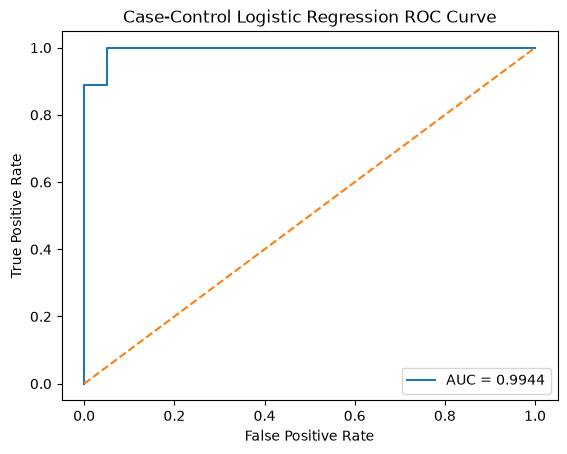

In [ ]:
#4a vii 
from sklearn.utils import resample

X_train, y_train = extract_segment_features(train_files, best_l)
train_data = X_train.copy()
train_data["label"] = y_train.values

bending = train_data[train_data["label"] == 1]
non_bending = train_data[train_data["label"] == 0]
non_bending_sample = resample(
    non_bending,
    replace=False,
    n_samples=len(bending),
    random_state=42 )

#balanced log reg
balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(estimator=LogisticRegression(max_iter=1000, C=1e6),
        n_features_to_select=best_p,
        step=0.2 )),
    ("logistic", LogisticRegression(
        max_iter=1000,
        C=1e6 ))  ])

balanced_data = pd.concat([bending, non_bending_sample])
X_balanced = balanced_data.drop(columns=["label"])
y_balanced = balanced_data["label"]

balanced_model.fit(X_balanced, y_balanced)
balanced_pred = balanced_model.predict(X_train)
balanced_prob = balanced_model.predict_proba(X_train)[:,1]

print("Confusion Matrix:")
print(confusion_matrix(y_train, balanced_pred))
print("AUC:", round(roc_auc_score(y_train, balanced_prob), 4))

# adjustments 
from scipy.special import expit, logit

original_p = y_train.mean()
sample_p = y_balanced.mean()
intercept_adjustment = logit(original_p) - logit(sample_p)
adjusted_prob = expit(logit(np.clip(balanced_prob, 1e-10, 1-1e-10)) + intercept_adjustment)

adjusted_pred = (adjusted_prob >= 0.5).astype(int)
print("Adjusted Confusion Matrix:\n", confusion_matrix(y_train, adjusted_pred))
print("intercept adjustment:", round(intercept_adjustment, 4))
print("adjusted AUC", round(roc_auc_score(y_train, adjusted_prob), 4))

#4a vii ROC
fpr, tpr, thresholds = roc_curve(y_train, adjusted_prob)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_train, adjusted_prob):.4f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression ROC Curve")
plt.legend()
plt.show()

In [20]:
#4c i 
def extract_multiclass_features(files, l):
    rows = []
    labels = []
    for file in files:
        df = load_arem_file(file)
        sensor_data = df.iloc[:, 1:]
        row = {}
        for i, col in enumerate(sensor_data.columns, start=1):
            values = sensor_data[col]
            segments = np.array_split(values.to_numpy(), l)
            for j, segment in enumerate(segments, start=1):
                row[f"sensor_{i}_part{j}_min"] = np.min(segment)
                row[f"sensor_{i}_part{j}_max"] = np.max(segment)
                row[f"sensor_{i}_part{j}_mean"] = np.mean(segment)
                row[f"sensor_{i}_part{j}_median"] = np.median(segment)
                row[f"sensor_{i}_part{j}_std"] = np.std(segment, ddof=1)
                row[f"sensor_{i}_part{j}_q1"] = np.percentile(segment, 25)
                row[f"sensor_{i}_part{j}_q3"] = np.percentile(segment, 75)
        rows.append(row)
        labels.append(file.parent.name)
    X = pd.DataFrame(rows)
    y = pd.Series(labels)
    return X, y


# multiclass labels verification
X_train_multi, y_train_multi = extract_multiclass_features(train_files, 1)
print("Training shape:", X_train_multi.shape)
print("Class distribution:")
print(y_train_multi.value_counts())

# more CV
#4c i cross validation
from sklearn.model_selection import GridSearchCV

cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42)

multi_results = []
C_values = [0.01,0.1,1,10]

for l in range(1,21):
    X,y = extract_multiclass_features(train_files, l)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=1000,
            tol=0.01,
            random_state=42 ))  ])

    grid = GridSearchCV(
        model,
        {"logistic__C": C_values},
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1 )

    grid.fit(X,y)

    multi_results.append({
        "l": l,
        "Best C": grid.best_params_["logistic__C"],
        "CV Accuracy": grid.best_score_ })

    print("Completed l =", l)

multi_cv_results = pd.DataFrame(multi_results)
display(
    multi_cv_results.sort_values(
        "CV Accuracy",
        ascending=False ).head(10))

Training shape: (69, 42)
Class distribution:
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

Completed l = 1
Completed l = 2


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

Completed l = 3


...

Completed l = 19


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' 

Completed l = 20


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,l,Best C,CV Accuracy
0,1,1,0.928105
1,2,1,0.898693
5,6,10,0.898693
4,5,10,0.883987
6,7,10,0.883987
2,3,10,0.869281
8,9,1,0.855392
10,11,10,0.855392
3,4,10,0.854575
11,12,10,0.840686


Test Accuracy: 0.8947
Test Error: 0.1053
Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


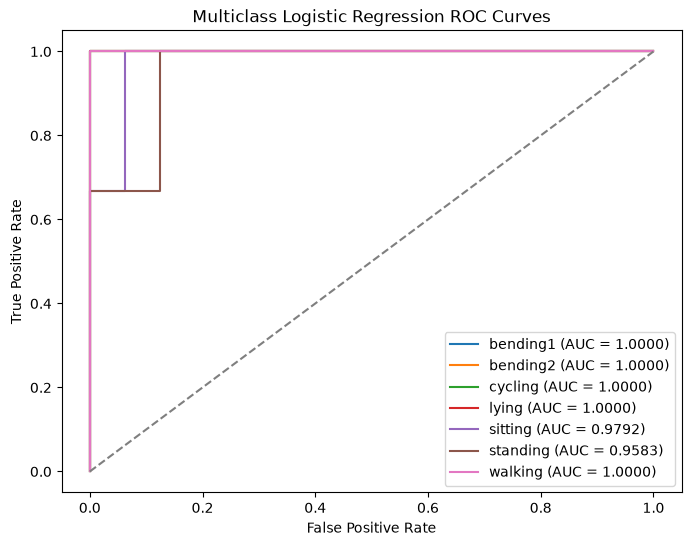

In [25]:
#4c i testing portion 
best_l_multi = 1
best_C_multi = 1

X_train_multi, y_train_multi = extract_multiclass_features(train_files, best_l_multi)
X_test_multi, y_test_multi = extract_multiclass_features(test_files, best_l_multi)

multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        solver="saga",
        C=best_C_multi,
        max_iter=1000,
        tol=0.01,
        random_state=42 ))  ])

multi_model.fit(X_train_multi, y_train_multi)
y_pred_multi = multi_model.predict(X_test_multi)
y_prob_multi = multi_model.predict_proba(X_test_multi)

print("Test Accuracy:", round(accuracy_score(y_test_multi, y_pred_multi), 4))
print("Test Error:", round(1 - accuracy_score(y_test_multi, y_pred_multi), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_test_multi, y_pred_multi,
    labels=multi_model.named_steps["logistic"].classes_))

#4c i multiclass ROC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = multi_model.named_steps["logistic"].classes_
y_test_bin = label_binarize(y_test_multi, classes=classes)
plt.figure(figsize=(8,6))

for i, activity in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:,i],
        y_prob_multi[:,i] )
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{activity} (AUC = {roc_auc:.4f})")

plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass Logistic Regression ROC Curves")
plt.legend()
plt.show()

In [ ]:
#4c ii Gaussian and Multinomial Naive Bayes

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd

#4c ii cross-validation

nb_results = [] 
for l in range(1,21):
    X,y = extract_multiclass_features(train_files, l)

    gaussian_model = GaussianNB()
    gaussian_scores = cross_val_score(
        gaussian_model,
        X,
        y,
        cv=cv_multi,
        scoring="accuracy" )

    multinomial_model = Pipeline([
        ("scaler", MinMaxScaler()),
        ("naive_bayes", MultinomialNB()) ])

    multinomial_scores = cross_val_score(
        multinomial_model,
        X,
        y,
        cv=cv_multi,
        scoring="accuracy" )

    nb_results.append({
        "l": l,
        "Gaussian CV Accuracy": gaussian_scores.mean(),
        "Multinomial CV Accuracy": multinomial_scores.mean() })

nb_cv_results = pd.DataFrame(nb_results)

display(nb_cv_results.sort_values(
    "Gaussian CV Accuracy",
    ascending=False ).head(10))


#4c ii best l selection
best_gaussian = nb_cv_results.sort_values(
    "Gaussian CV Accuracy",
    ascending=False ).iloc[0]

best_multinomial = nb_cv_results.sort_values(
    "Multinomial CV Accuracy",
    ascending=False ).iloc[0]

best_l_gaussian = int(best_gaussian["l"])
best_l_multinomial = int(best_multinomial["l"])

print("Best Gaussian l:", best_l_gaussian)
print("Gaussian CV Accuracy:", round(best_gaussian["Gaussian CV Accuracy"], 4))

print("Best Multinomial l:", best_l_multinomial)
print("Multinomial CV Accuracy:", round(best_multinomial["Multinomial CV Accuracy"], 4))


#4c ii Gaussian Naive Bayes testing

X_train_gaussian, y_train_gaussian = extract_multiclass_features(
    train_files, best_l_gaussian)

X_test_gaussian, y_test_gaussian = extract_multiclass_features(
    test_files, best_l_gaussian)

gaussian_model = GaussianNB()
gaussian_model.fit(X_train_gaussian, y_train_gaussian)

gaussian_pred = gaussian_model.predict(X_test_gaussian)

print("Gaussian NB Test Accuracy:", round(accuracy_score(y_test_gaussian, gaussian_pred), 4))
print("Gaussian NB Test Error:", round(1 - accuracy_score(y_test_gaussian, gaussian_pred), 4))
print("Gaussian NB Confusion Matrix:")
print(confusion_matrix(y_test_gaussian, gaussian_pred,
    labels=gaussian_model.classes_))


#4c ii Multinomial Naive Bayes testing
X_train_multinomial, y_train_multinomial = extract_multiclass_features(
    train_files, best_l_multinomial)

X_test_multinomial, y_test_multinomial = extract_multiclass_features(
    test_files, best

# ISLR 4.8.3
The Bayes classifier assigns the observation to the class with the largest discriminant function. As the class-specific variances are not assumed to be equal, the discriminant functions consists of quadratic terms in x that don't cancel when comparing classes. Therefore, the resulting decision boundaries are quadratic rather than linear. This demonstrates decision boundaries are quadratic rather than linear. This demonstrates why QDA is a quadratic classifier. In the unique case of equal variances, the quadratic terms cancel, which reduces the classifier to LDA. 


# ISLR 4.8.7
The probability that a company will issue a dividend this year with the profit of 4% from the previous year, results in approximately 75.19%. This conclusion is greater than 50%, so the Bayes classifier predicts that the company will issue a dividend. 